# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35, random_state=42)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,822,95,41,82,170,65,9,145,46,19,145,163,314,140,64,4,8,199,207
1,486,104,57,103,222,72,12,221,30,25,177,223,718,218,72,11,12,186,195
2,182,91,42,66,169,66,7,145,44,19,140,169,325,159,67,4,0,201,207
3,375,109,52,95,189,58,4,227,29,25,158,262,776,217,82,0,19,187,186
4,528,95,47,73,195,70,7,167,38,20,152,184,430,185,69,9,19,200,206
5,223,81,44,72,139,60,6,153,44,19,146,180,347,178,81,1,15,182,186
6,840,93,34,66,140,56,7,130,51,18,120,151,251,114,62,5,29,201,207
7,593,89,43,77,147,54,8,144,46,19,146,163,308,174,64,13,5,194,201
8,346,117,52,110,228,65,12,212,31,24,163,228,668,220,66,21,25,194,205
9,357,109,49,109,193,59,10,207,32,24,156,225,635,213,70,13,31,191,202


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,425.723133,93.520947,44.675774,81.801457,168.204007,61.644809,8.457195,167.327869,41.273224,20.468124,147.438980,186.734062,431.540984,173.763206,72.158470,6.522769,12.646630,188.998179,195.854281
std,242.288797,8.063277,6.154680,15.928751,33.047995,7.110666,3.945857,32.506680,7.777590,2.526030,14.631309,30.436279,171.479332,31.793047,7.335198,4.980796,8.833356,6.298389,7.449629
min,0.000000,76.000000,33.000000,42.000000,104.000000,47.000000,2.000000,114.000000,26.000000,17.000000,118.000000,131.000000,191.000000,112.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,217.000000,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,146.000000,34.000000,19.000000,136.000000,167.000000,317.000000,148.000000,67.000000,2.000000,6.000000,184.000000,191.000000
50%,430.000000,93.000000,44.000000,79.000000,165.000000,61.000000,8.000000,157.000000,43.000000,20.000000,145.000000,177.000000,363.000000,173.000000,71.000000,6.000000,11.000000,189.000000,197.000000
75%,636.000000,99.000000,49.000000,98.000000,195.000000,66.000000,10.000000,196.000000,46.000000,23.000000,159.000000,216.000000,576.000000,196.000000,75.000000,10.000000,19.000000,193.000000,201.000000
max,845.000000,117.000000,59.000000,110.000000,306.000000,126.000000,52.000000,265.000000,59.000000,29.000000,186.000000,288.000000,1018.000000,268.000000,127.000000,22.000000,40.000000,206.000000,211.000000


In [5]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [6]:
# Столбец 0 — сквозной индекс объекта (0..845), а не признак: удаляем его.
X_train = X_train[:, 1:]
X_test = X_test[:, 1:]

print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (549, 18) | X_test: (297, 18)


**Что сделано и почему.**

- Удалён столбец 0: в исходном CSV это сквозной индекс объекта (0…845), не несущий информации о силуэте. Если оставить его признаком, модель сможет «выучить» порядок строк, а PCA и расстояния будут искажены.
- Остальные 18 признаков не менялись: пропусков, дубликатов и константных признаков в данных нет.
- Масштабирование здесь не выполняем: `StandardScaler` будет внутри `Pipeline` перед PCA и логистической регрессией, чтобы `fit` происходил только на train и не было утечки из test. Деревья к масштабу нечувствительны.

Итоговые формы: `X_train` — (549, 18), `X_test` — (297, 18).

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

Лучшие гиперпараметры: {'C': 1.0, 'penalty': 'l1'}
CV f1_macro: 0.704
Accuracy: 0.721
F1 macro: 0.700

              precision    recall  f1-score   support

         bus      0.810     0.942     0.871        86
        opel      0.481     0.633     0.547        60
        saab      0.732     0.357     0.480        84
         van      0.844     0.970     0.903        67

    accuracy                          0.721       297
   macro avg      0.717     0.726     0.700       297
weighted avg      0.729     0.721     0.702       297



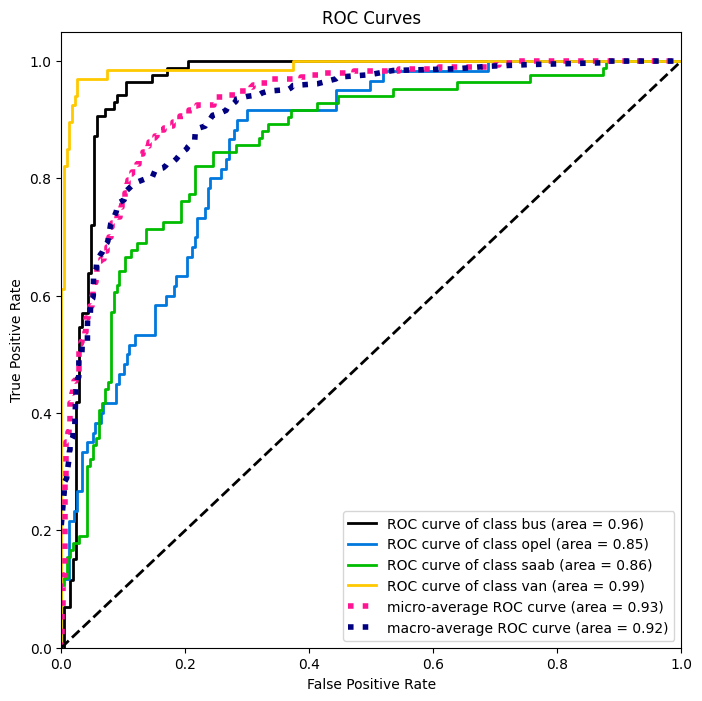

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import scikitplot as skplt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Версия под sklearn < 1.7 (в 1.7+ параметр multi_class удалён).
log_reg = LogisticRegression(
    multi_class='multinomial', solver='saga', tol=1e-3, max_iter=500, random_state=42
)

param_grid = {
    'penalty': ['l1', 'l2'],
    'C': np.logspace(-3, 3, 5),
}

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
grid = GridSearchCV(log_reg, param_grid, cv=cv, scoring='f1_macro')
grid.fit(X_train, y_train)

print('Лучшие гиперпараметры:', grid.best_params_)
print('CV f1_macro: %.3f' % grid.best_score_)

best_log_reg = grid.best_estimator_
y_pred = best_log_reg.predict(X_test)

print('Accuracy: %.3f' % accuracy_score(y_test, y_pred))
print('F1 macro: %.3f' % f1_score(y_test, y_pred, average='macro'))
print()
print(classification_report(y_test, y_pred, digits=3))

# ROC-кривые one-vs-rest для каждого из 4 классов
skplt.metrics.plot_roc(y_test, best_log_reg.predict_proba(X_test), figsize=(8, 8))
plt.show()

**Результаты.** Лучшая комбинация — `penalty='l1'`, `C=1.0`; CV `f1_macro` ≈ 0.70. Вариант `penalty='l2'` даёт тот же CV-скор, выбор между L1 и L2 на этой сетке непринципиален.

На тестовой части: accuracy ≈ 0.72, `f1_macro` ≈ 0.70. По классам:

| Класс | precision | recall | f1 |
|---|---|---|---|
| bus | 0.81 | 0.94 | 0.87 |
| opel | 0.48 | 0.63 | 0.55 |
| saab | 0.73 | 0.36 | 0.48 |
| van | 0.84 | 0.97 | 0.90 |

`bus` и `van` разделяются хорошо, `opel` и особенно `saab` — плохо. Это согласуется с описанием датасета: авторы отмечали, что два легковых автомобиля близки по силуэту, а разброс внутри класса во многом вызван ракурсом съёмки. ROC построен в режиме one-vs-rest через `scikitplot`. AUC: `bus` 0.960, `opel` 0.851, `saab` 0.856, `van` 0.990 — у `opel` и `saab` кривые заметно ниже остальных.

`C` — обратная сила регуляризации: маленькое `C` сильнее штрафует веса; лучшее значение на сетке — 1.0, то есть данные не требуют сильной регуляризации.

In [8]:
# You might use this command to install scikit-plot. 
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding 
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot. 

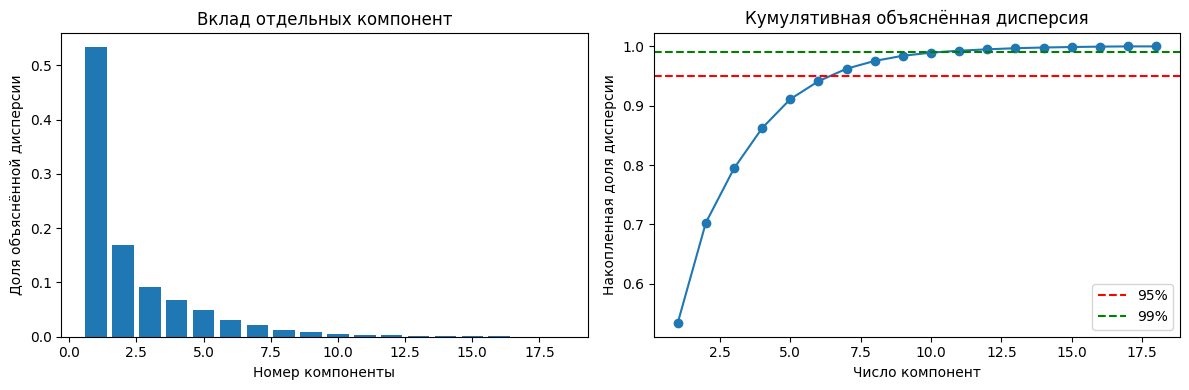

90% дисперсии: 5 компонент
95% дисперсии: 7 компонент
99% дисперсии: 11 компонент


In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# PCA ищет направления максимальной дисперсии, поэтому признаки нужно
# привести к одному масштабу: их диапазоны различаются на порядки (17...29 и 184...1018).
# scaler обучаем только на train — иначе статистики теста "протекут" в обучение.
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)

pca_full = PCA().fit(X_train_scaled)
explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(np.arange(1, len(explained) + 1), explained)
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Доля объяснённой дисперсии')
axes[0].set_title('Вклад отдельных компонент')

axes[1].plot(np.arange(1, len(cum_explained) + 1), cum_explained, marker='o')
axes[1].axhline(0.95, color='red', linestyle='--', label='95%')
axes[1].axhline(0.99, color='green', linestyle='--', label='99%')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Накопленная доля дисперсии')
axes[1].set_title('Кумулятивная объяснённая дисперсия')
axes[1].legend()

plt.tight_layout()
plt.show()

for threshold in (0.90, 0.95, 0.99):
    n = int(np.searchsorted(cum_explained, threshold) + 1)
    print(f'{threshold:.0%} дисперсии: {n} компонент')


**Результаты.** Первые две компоненты объясняют около 70% дисперсии, пять — 91%, семь — 96%, одиннадцать — 99%. Кривая быстро выходит на плато: после 7–8 компонент каждая следующая добавляет меньше 1–2%. Это ожидаемо: в данных 14 пар признаков с корреляцией выше 0.9, то есть 18 исходных признаков описывают заметно меньше независимых направлений.

Стандартизация здесь принципиальна. `PCA` центрирует данные, но не масштабирует: без `StandardScaler` направления максимальной дисперсии определялись бы признаками с самыми большими абсолютными значениями (например, `SCALED VARIANCE ALONG MINOR AXIS` с диапазоном 184…1018), а не общей структурой силуэтов. После масштабирования каждый признак входит с весом $1/\sigma$, и компоненты отражают корреляции между признаками.

`fit` scaler и PCA выполнен только на train — тестовая часть не участвовала в выборе средних, разбросов и базиса.


#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [10]:
# Минимальное число компонент, дающее >= 95% объяснённой дисперсии.
N_COMPONENTS = 7

pca = PCA(n_components=N_COMPONENTS).fit(X_train_scaled)
X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(scaler.transform(X_test))

print('X_train_pca:', X_train_pca.shape, '| X_test_pca:', X_test_pca.shape)
print('Сохранено дисперсии: %.3f' % pca.explained_variance_ratio_.sum())


X_train_pca: (549, 7) | X_test_pca: (297, 7)
Сохранено дисперсии: 0.962


**Выбор числа компонент.** Беру 7 компонент — это минимальное число, при котором накопленная дисперсия превышает 95% (получается около 96.2%). Оставшиеся 11 компонент добавляют меньше 4% и, судя по графику, описывают в основном шум. Порог 99% потребовал бы 11 компонент — почти двукратный рост размерности ради 3% дисперсии; в п. 2.4 проверю, что усечение до 7 не ухудшает качество классификации.

**Нужно ли нормализовать данные?** Да, и это сделано выше. `PCA` центрирует признаки, но не приводит их к единому масштабу, а исходные признаки измеряются в разных единицах и имеют разные диапазоны (17…29 против 184…1018). Без стандартизации первая компонента почти совпала бы с одним «крупным» признаком, а не с направлением совместной изменчивости. После `StandardScaler` дисперсия каждого признака равна 1, и вклад определяется корреляционной структурой.

К тесту применяется только `transform` с параметрами, найденными на train: `fit_transform` на тесте означал бы утечку — средние, разбросы и базис PCA «подсмотрели» бы тестовые объекты.


**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

Лучшие гиперпараметры: {'log_reg__C': 31.622776601683793, 'log_reg__penalty': 'l1'}
CV f1_macro: 0.559
Accuracy: 0.636
F1 macro: 0.624

              precision    recall  f1-score   support

         bus      0.688     0.744     0.715        86
        opel      0.413     0.517     0.459        60
        saab      0.702     0.393     0.504        84
         van      0.744     0.910     0.819        67

    accuracy                          0.636       297
   macro avg      0.637     0.641     0.624       297
weighted avg      0.649     0.636     0.627       297



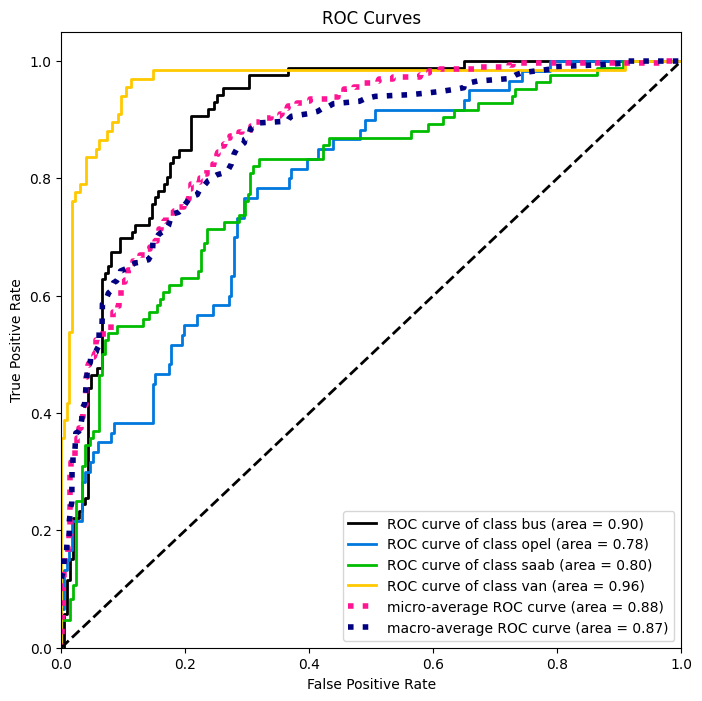

In [11]:
from sklearn.pipeline import Pipeline

# Pipeline обучает scaler и PCA на train-фолде и применяет их к validation,
# поэтому утечки нет: параметры преобразования не видят тестовых объектов.
pca_log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=N_COMPONENTS)),
    ('log_reg', LogisticRegression(
        multi_class='multinomial', solver='saga',
        tol=1e-3, max_iter=500, random_state=42,
    )),
])

param_grid_pca = {
    'log_reg__penalty': ['l1', 'l2'],
    'log_reg__C': np.logspace(-3, 3, 5),
}
cv_pca = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

grid_pca = GridSearchCV(pca_log_reg, param_grid_pca, cv=cv_pca, scoring='f1_macro')
grid_pca.fit(X_train, y_train)

print('Лучшие гиперпараметры:', grid_pca.best_params_)
print('CV f1_macro: %.3f' % grid_pca.best_score_)

y_pred_pca = grid_pca.predict(X_test)
print('Accuracy: %.3f' % accuracy_score(y_test, y_pred_pca))
print('F1 macro: %.3f' % f1_score(y_test, y_pred_pca, average='macro'))
print()
print(classification_report(y_test, y_pred_pca, digits=3))

skplt.metrics.plot_roc(y_test, grid_pca.predict_proba(X_test), figsize=(8, 8))
plt.show()


**Результаты.** Лучшая комбинация — `penalty='l1'`, `C=31.6`; CV `f1_macro` = 0.559. На тесте accuracy = 0.636, `f1_macro` = 0.624. По классам: `bus` 0.715, `opel` 0.459, `saab` 0.504, `van` 0.819. AUC: `bus` 0.904, `opel` 0.781, `saab` 0.803, `van` 0.964.

Сравнение с п. 2.1:

| Модель | CV f1_macro | accuracy | f1_macro |
|---|---|---|---|
| 2.1: LogReg на 18 исходных признаках (без масштабирования) | 0.704 | 0.721 | 0.700 |
| 2.4: `StandardScaler → PCA(7) → LogReg` | 0.559 | 0.636 | 0.624 |

Метрики заметно упали, но сравнение не чистое: в 2.4 изменились сразу два фактора — появилась стандартизация и появилось сжатие до 7 компонент. `saga` очень чувствительна к масштабу признаков, поэтому стандартизация должна была помочь. Отделить её вклад от вклада PCA позволяет следующий эксперимент с разным числом компонент.

Причина падения в том, что PCA максимизирует **дисперсию**, а не **разделимость классов**. Семь компонент сохраняют 96.2% общего разброса, но отбрасывают направления с малой дисперсией — а именно в них могут лежать тонкие различия между `opel` и `saab`. Для классификации эти направления могут быть важнее, чем самые «размазанные».


In [12]:
# Проверяем, сколько компонент действительно нужно для классификации:
# перебираем n_components вместе с гиперпараметрами LogReg.
pca_log_reg_full = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('log_reg', LogisticRegression(
        multi_class='multinomial', solver='saga',
        tol=1e-3, max_iter=500, random_state=42,
    )),
])

param_grid_full = {
    'pca__n_components': [7, 11, 13, 18],
    'log_reg__penalty': ['l1', 'l2'],
    'log_reg__C': np.logspace(-3, 3, 5),
}

grid_full = GridSearchCV(pca_log_reg_full, param_grid_full, cv=cv_pca, scoring='f1_macro')
grid_full.fit(X_train, y_train)

y_pred_full = grid_full.predict(X_test)
print('Лучшие параметры:', grid_full.best_params_)
print('CV f1_macro: %.3f' % grid_full.best_score_)
print('Accuracy: %.3f' % accuracy_score(y_test, y_pred_full))
print('F1 macro: %.3f' % f1_score(y_test, y_pred_full, average='macro'))
print()

# Лучшее CV-качество для каждого числа компонент.
best_by_n = {}
for params, mean_score in zip(grid_full.cv_results_['params'],
                              grid_full.cv_results_['mean_test_score']):
    n = params['pca__n_components']
    if n not in best_by_n or mean_score > best_by_n[n][0]:
        best_by_n[n] = (mean_score, params)

for n in sorted(best_by_n):
    score, params = best_by_n[n]
    print('n_components=%2d: CV f1_macro=%.3f  (%s, C=%.3g)'
          % (n, score, params['log_reg__penalty'], params['log_reg__C']))


Лучшие параметры: {'log_reg__C': 31.622776601683793, 'log_reg__penalty': 'l1', 'pca__n_components': 18}
CV f1_macro: 0.798
Accuracy: 0.832
F1 macro: 0.825

n_components= 7: CV f1_macro=0.559  (l1, C=31.6)
n_components=11: CV f1_macro=0.736  (l1, C=1)
n_components=13: CV f1_macro=0.774  (l1, C=31.6)
n_components=18: CV f1_macro=0.798  (l1, C=31.6)


**Вывод.** Качество монотонно растёт с числом компонент: 7 → 0.559, 11 → 0.736, 13 → 0.774, 18 → 0.798 по CV `f1_macro`. Лучший вариант — вообще без сжатия (все 18 компонент, то есть PCA работает как поворот без потери информации). Значит, для этой задачи PCA **не помогает** классификации: направления, различающие классы, имеют малую дисперсию и при усечении теряются первыми. Правило «95% дисперсии» хорошо для сжатия и визуализации, но не гарантирует сохранения полезной для предсказания информации.

При этом стандартизация действительно полезна: та же LogReg на 18 стандартизованных признаках даёт accuracy 0.832 и `f1_macro` 0.825 против 0.721/0.700 в п. 2.1 без масштабирования. То есть основной выигрыш в этой части даёт `StandardScaler` (для `saga` это критично), а не PCA. PCA(7) при этом остаётся разумным компромиссом только если важнее скорость и компактность модели, а не максимальное качество.


#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

# Деревья инвариантны к масштабу признаков: пороги расщепления не меняются
# при монотонном преобразовании, поэтому StandardScaler здесь не нужен.
depths = list(range(2, 21))

tree = DecisionTreeClassifier(random_state=42)
cv_tree = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

grid_tree = GridSearchCV(tree, {'max_depth': depths}, cv=cv_tree, scoring='f1_macro')
grid_tree.fit(X_train, y_train)

print('Лучшая глубина:', grid_tree.best_params_['max_depth'])
print('CV f1_macro: %.3f' % grid_tree.best_score_)

y_pred_tree = grid_tree.predict(X_test)
print('Accuracy: %.3f' % accuracy_score(y_test, y_pred_tree))
print('F1 macro: %.3f' % f1_score(y_test, y_pred_tree, average='macro'))
print()
print(classification_report(y_test, y_pred_tree, digits=3))


Лучшая глубина: 11
CV f1_macro: 0.705
Accuracy: 0.741
F1 macro: 0.732

              precision    recall  f1-score   support

         bus      0.903     0.977     0.939        86
        opel      0.529     0.617     0.569        60
        saab      0.618     0.560     0.588        84
         van      0.897     0.776     0.832        67

    accuracy                          0.741       297
   macro avg      0.737     0.732     0.732       297
weighted avg      0.745     0.741     0.741       297



**Результаты.** CV выбирает `max_depth=11`: CV `f1_macro` = 0.705. На тесте accuracy = 0.741, `f1_macro` = 0.732. По классам: `bus` 0.939, `opel` 0.569, `saab` 0.588, `van` 0.832. У выбранного дерева 91 лист.

Для сравнения: LogReg на исходных признаках дала 0.721/0.700 (п. 2.1), на PCA(7) — 0.636/0.624 (п. 2.4). Дерево лучше обеих. Стандартизация ему не нужна — пороги расщепления инвариантны к монотонным преобразованиям признаков, поэтому масштаб не влияет на структуру дерева. Выигрыш даёт нелинейность: дерево строит кусочно-постоянные границы и само находит взаимодействия признаков (например, «длинный и одновременно узкий» силуэт), которые LogReg моделирует только через явные произведения признаков.


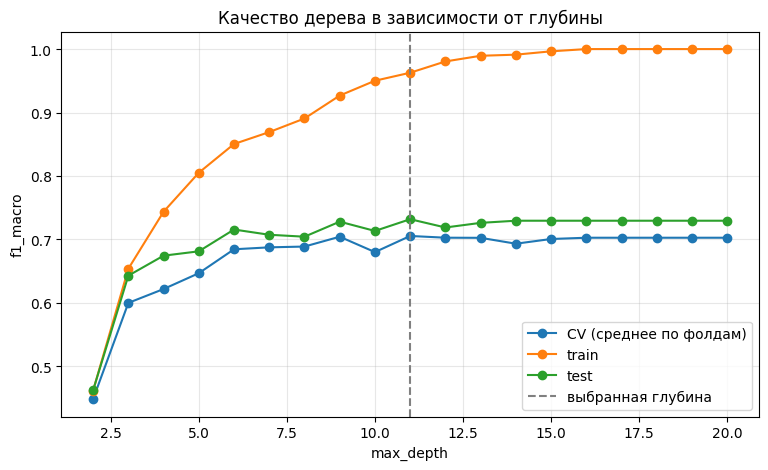

In [14]:
cv_scores, train_scores, test_scores = [], [], []

for depth in depths:
    cv_scores.append(cross_val_score(
        DecisionTreeClassifier(max_depth=depth, random_state=42),
        X_train, y_train, cv=cv_tree, scoring='f1_macro').mean())

    model = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    train_scores.append(f1_score(y_train, model.predict(X_train), average='macro'))
    test_scores.append(f1_score(y_test, model.predict(X_test), average='macro'))

plt.figure(figsize=(9, 5))
plt.plot(depths, cv_scores, marker='o', label='CV (среднее по фолдам)')
plt.plot(depths, train_scores, marker='o', label='train')
plt.plot(depths, test_scores, marker='o', label='test')
plt.axvline(grid_tree.best_params_['max_depth'], color='grey', linestyle='--',
            label='выбранная глубина')
plt.xlabel('max_depth')
plt.ylabel('f1_macro')
plt.title('Качество дерева в зависимости от глубины')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Как глубина ограничивает переобучение.** На train `f1_macro` растёт почти до 1.0 (при глубине около 16 дерево запоминает всю обучающую выборку). Тестовая кривая после 9–11 уровней выходит на плато около 0.73, а CV-кривая держится около 0.70. Дальнейшее углубление не улучшает обобщение, но увеличивает сложность модели и дисперсию: дерево становится чувствительным к конкретным объектам train.

`max_depth` — грубый, но действенный регуляризатор: он ограничивает число последовательных разбиений, а значит и максимальную сложность кусочно-постоянной функции. Альтернативы — `min_samples_leaf`, `min_samples_split` и пост-прунинг через `ccp_alpha`. Выбирать значение нужно по CV, а не по train: train-метрика растёт вплоть до полного запоминания и о качестве на новых данных ничего не говорит.

Разница между глубинами 9, 11 и 12 по CV мала (0.704, 0.705, 0.703) — это в пределах разброса по фолдам, поэтому конкретное значение не стоит трактовать слишком буквально. Отмечу на будущее: для бэггинга в п. 2.6 нужны, наоборот, глубокие деревья — там дисперсию снижает усреднение по ансамблю, а не ограничение глубины.


#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble? 

In [15]:
import warnings

from sklearn.exceptions import ConvergenceWarning

N_MIN, N_MAX, STEP = 2, 100, 5
n_values = list(range(N_MIN, N_MAX, STEP))

# Бутстрап-выборки генерируем один раз: ансамбль из N моделей — это первые N
# обученных моделей, поэтому все точки кривой считаются за один проход.
rng = np.random.RandomState(42)
bootstrap_idx = [rng.randint(0, len(y_train), len(y_train))
                 for _ in range(n_values[-1])]


def bagging_curve(make_model):
    """Обучает модель на каждой бутстрап-выборке и усредняет вероятности
    первых N моделей (soft voting). Возвращает accuracy и f1_macro для всех N."""
    models = [make_model().fit(X_train[i], y_train[i]) for i in bootstrap_idx]
    classes = models[0].classes_

    accs, f1s = [], []
    proba_sum = np.zeros((len(y_test), len(classes)))
    for n, model in enumerate(models, start=1):
        proba_sum += model.predict_proba(X_test)
        if n in n_values:
            y_pred = classes[proba_sum.argmax(axis=1)]
            accs.append(accuracy_score(y_test, y_pred))
            f1s.append(f1_score(y_test, y_pred, average='macro'))
    return accs, f1s


def make_log_reg():
    return LogisticRegression(
        penalty='l1', C=1.0, multi_class='multinomial',
        solver='saga', tol=1e-3, max_iter=500, random_state=42,
    )


# На части бутстрап-выборок saga с L1 не успевает сойтись за 500 итераций.
# Для сравнения кривых это не критично, поэтому предупреждение глушим локально.
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    acc_lr, f1_lr = bagging_curve(make_log_reg)
acc_dt, f1_dt = bagging_curve(lambda: DecisionTreeClassifier(random_state=42))
acc_dt11, f1_dt11 = bagging_curve(
    lambda: DecisionTreeClassifier(max_depth=11, random_state=42)
)

print('   N | LR   acc / f1  | DT   acc / f1  | DT11 acc / f1')
for n, alr, flr, adt, fdt, a11, f11 in zip(
        n_values, acc_lr, f1_lr, acc_dt, f1_dt, acc_dt11, f1_dt11):
    print('%4d | %.3f / %.3f | %.3f / %.3f | %.3f / %.3f'
          % (n, alr, flr, adt, fdt, a11, f11))

print()
print('Влияние глубины базового дерева (N=97):')
for depth in (4, 6, 11, None):
    accs, f1s = bagging_curve(
        lambda depth=depth: DecisionTreeClassifier(max_depth=depth, random_state=42))
    print('max_depth=%-4s: accuracy=%.3f, f1_macro=%.3f'
          % (depth, accs[-1], f1s[-1]))


   N | LR   acc / f1  | DT   acc / f1  | DT11 acc / f1
   2 | 0.737 / 0.720 | 0.657 / 0.638 | 0.680 / 0.667
   7 | 0.734 / 0.715 | 0.700 / 0.693 | 0.714 / 0.705
  12 | 0.710 / 0.687 | 0.744 / 0.737 | 0.744 / 0.735
  17 | 0.717 / 0.695 | 0.744 / 0.733 | 0.751 / 0.740
  22 | 0.710 / 0.687 | 0.758 / 0.747 | 0.768 / 0.757
  27 | 0.717 / 0.695 | 0.764 / 0.755 | 0.774 / 0.765
  32 | 0.717 / 0.695 | 0.771 / 0.761 | 0.758 / 0.747
  37 | 0.714 / 0.691 | 0.768 / 0.758 | 0.751 / 0.740
  42 | 0.710 / 0.688 | 0.764 / 0.755 | 0.768 / 0.758
  47 | 0.714 / 0.691 | 0.764 / 0.754 | 0.764 / 0.754
  52 | 0.717 / 0.695 | 0.768 / 0.757 | 0.764 / 0.754
  57 | 0.710 / 0.687 | 0.768 / 0.757 | 0.758 / 0.746
  62 | 0.710 / 0.687 | 0.764 / 0.753 | 0.761 / 0.750
  67 | 0.717 / 0.695 | 0.764 / 0.753 | 0.754 / 0.744
  72 | 0.714 / 0.691 | 0.761 / 0.751 | 0.758 / 0.748
  77 | 0.717 / 0.695 | 0.761 / 0.752 | 0.754 / 0.744
  82 | 0.721 / 0.698 | 0.764 / 0.754 | 0.758 / 0.748
  87 | 0.721 / 0.698 | 0.754 / 0.745 | 0.764

max_depth=6   : accuracy=0.717, f1_macro=0.702
max_depth=11  : accuracy=0.761, f1_macro=0.752


max_depth=None: accuracy=0.758, f1_macro=0.748


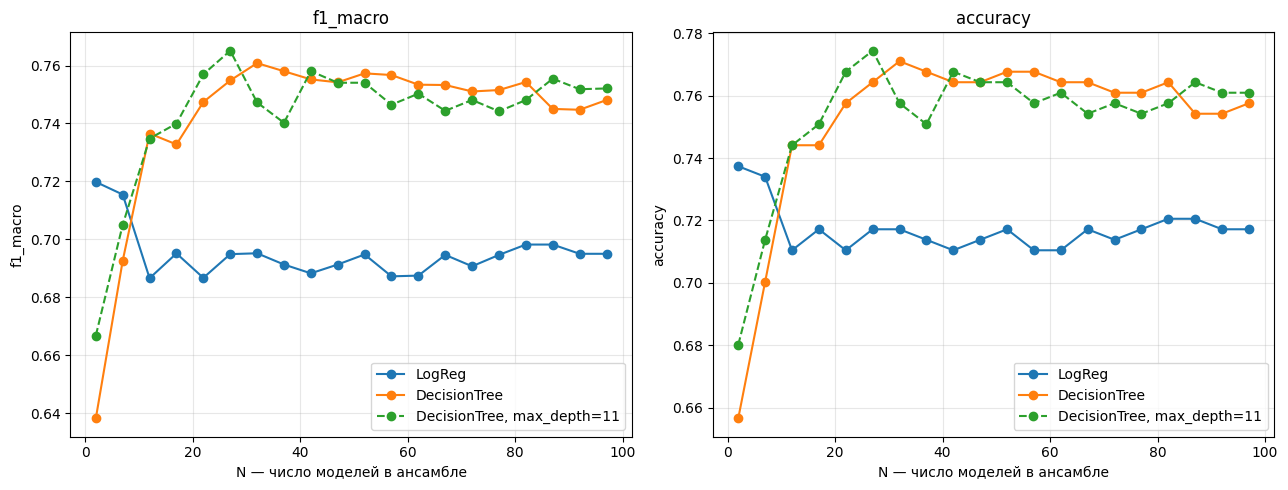

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, scores_lr, scores_dt, scores_dt11, metric in (
        (axes[0], f1_lr, f1_dt, f1_dt11, 'f1_macro'),
        (axes[1], acc_lr, acc_dt, acc_dt11, 'accuracy')):
    ax.plot(n_values, scores_lr, marker='o', label='LogReg')
    ax.plot(n_values, scores_dt, marker='o', label='DecisionTree')
    ax.plot(n_values, scores_dt11, marker='o', linestyle='--',
            label='DecisionTree, max_depth=11')
    ax.set_xlabel('N — число моделей в ансамбле')
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


**Результаты.** На графиках видны два принципиально разных поведения.

**LogReg: бэггинг не помогает.** Одиночная LogReg из 2.1 даёт accuracy 0.721 и `f1_macro` 0.700, а ансамбль выходит на плато около 0.717/0.695 — чуть **хуже** одиночной модели. Причина в том, что бэггинг снижает **дисперсию**, а линейная модель с L1-регуляризацией и так стабильна: разные бутстрап-выборки дают почти одинаковые веса. При этом каждый базовый классификатор обучается примерно на 63% уникальных объектов, то есть на меньших данных, и его смещение немного растёт. Усреднение не возвращает эту потерянную информацию. Дополнительный штрих: на части бутстрап-выборок `saga` с L1 не успевает сойтись за `max_iter=500` — ещё один признак, что LogReg здесь не лучший кандидат для бэггинга (на сравнение кривых это не влияет).

**DecisionTree: бэггинг работает.** Одиночное неограниченное дерево даёт 0.737/0.729, ансамбль выходит на плато при N ≈ 30–40: при N = 32 accuracy 0.771, `f1_macro` 0.761. Дальше кривые колеблются около 0.76 без устойчивого роста. Оптимально брать **N ≈ 30–40**: дополнительные деревья почти не меняют качество.

Почему плато наступает: дисперсия ансамбля из N моделей примерно равна

$$\mathrm{Var} \approx \rho\sigma^2 + \frac{1-\rho}{N}\sigma^2,$$

где $\sigma^2$ — дисперсия одного дерева, $\rho$ — корреляция предсказаний разных деревьев. При $N \to \infty$ остаётся $\rho\sigma^2$: деревья обучены на похожих (пересекающихся) бутстрап-выборках, поэтому корреляция не нулевая, и наращивание ансамбля упирается в этот предел. Отсюда же и разница с Random Forest в 2.7, где признаковый случайный отбор уменьшает $\rho$.

**Оптимальны ли гиперпараметры дерева из 2.5 для ансамбля?** Формально нет: `max_depth=11` подбирался, чтобы ограничить переобучение **одиночного** дерева, а в бэггинге дисперсию снижает усреднение, поэтому базовые деревья должны быть низкосмещёнными — глубокими. Но на этом датасете ограничение до 11 практически не вредит: дерево глубины 11 уже достаточно сложное (91 лист, train `f1_macro` 0.963), и его ансамбль даёт 0.774/0.765 (лучшая точка N = 27) против 0.771/0.761 у неограниченных деревьев — разница в пределах шума. А вот действительно мелкие деревья плохи: при N = 97 бэггинг с `max_depth=4` даёт 0.680/0.655, с `max_depth=6` — 0.717/0.702. Вывод: для ансамбля нужны деревья с малой глубиной смещения; depth 11 из 2.5 уже удовлетворяет этому, но специально подбирать его заново под бэггинг не требуется — проще брать деревья без ограничения глубины.


#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

In [17]:
from sklearn.ensemble import RandomForestClassifier

n_trees = list(range(1, 101))
rf_acc, rf_f1 = [], []

for n in n_trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    rf_acc.append(accuracy_score(y_test, y_pred_rf))
    rf_f1.append(f1_score(y_test, y_pred_rf, average='macro'))

best_n = n_trees[int(np.argmax(rf_f1))]
print('Лучшее число деревьев: %d' % best_n)
print('Accuracy: %.3f' % rf_acc[best_n - 1])
print('F1 macro: %.3f' % rf_f1[best_n - 1])
print()

best_rf = RandomForestClassifier(n_estimators=best_n, random_state=42).fit(X_train, y_train)
print(classification_report(y_test, best_rf.predict(X_test), digits=3))


Лучшее число деревьев: 39
Accuracy: 0.768
F1 macro: 0.759

              precision    recall  f1-score   support

         bus      0.955     0.988     0.971        86
        opel      0.500     0.633     0.559        60
        saab      0.636     0.500     0.560        84
         van      0.955     0.940     0.947        67

    accuracy                          0.768       297
   macro avg      0.761     0.766     0.759       297
weighted avg      0.773     0.768     0.766       297



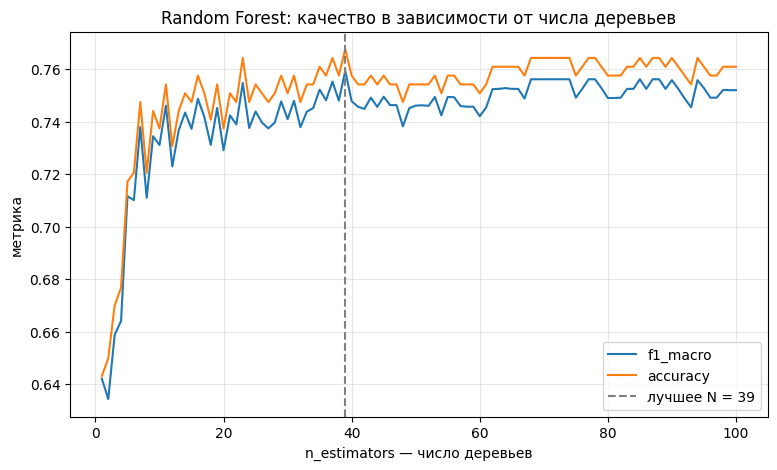

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(n_trees, rf_f1, label='f1_macro')
plt.plot(n_trees, rf_acc, label='accuracy')
plt.axvline(best_n, color='grey', linestyle='--', label='лучшее N = %d' % best_n)
plt.xlabel('n_estimators — число деревьев')
plt.ylabel('метрика')
plt.title('Random Forest: качество в зависимости от числа деревьев')
plt.grid(alpha=0.3)
plt.legend()
plt.show()


**Результаты.** Лучшая точка — `n_estimators=39`: accuracy 0.768, `f1_macro` 0.759. По классам: `bus` 0.971, `opel` 0.559, `saab` 0.560, `van` 0.947. Кривая выходит на плато уже при N ≈ 20–25: начиная с N = 23 качество отличается от максимума меньше чем на 0.005, дальше идут колебания примерно ±0.01. Одно дерево даёт 0.643/0.642, десять — 0.737/0.731, то есть основной прирост приходится на первые 10–20 деревьев.

**Сравнение с бэггингом из 2.6.** Оптимальное число деревьев практически то же: у бэггинга плато N ≈ 30–40 (лучшая точка 32 для неограниченных деревьев), у Random Forest — 39. Качество тоже сопоставимо: 0.768/0.759 у RF против 0.771/0.761 у бэггинга неограниченных деревьев и 0.774/0.765 у бэггинга `max_depth=11` — различия в пределах шума.

Почему заметного выигрыша нет:

- Random Forest уменьшает корреляцию $\rho$ между деревьями за счёт случайного поднабора признаков на каждом разбиении (по умолчанию `max_features='sqrt'`, то есть 4 из 18). По формуле $\mathrm{Var} \approx \rho\sigma^2 + \frac{1-\rho}{N}\sigma^2$ это должно снижать плато по сравнению с бэггингом.
- Но признаки в этом датасете сильно коррелированы (14 пар с $r > 0.9$), поэтому случайные подмножества всё равно содержат почти ту же информацию, и $\rho$ падает слабо.
- При 18 признаках $\sqrt{18} \approx 4$ — довольно агрессивное ограничение: часть разбиений строится без самых сильных признаков (`elongatedness`, `scatter ratio`). Число деревьев это компенсирует, но большого прироста не возникает.

**Почему у числа деревьев есть «оптимум».** С ростом N Random Forest не переобучается: теоретическое качество только приближается к пределу $\rho\sigma^2$ снизу. Наблюдаемые колебания — шум конечной тестовой выборки (297 объектов): на другом сплите «лучшее» N окажется другим. Поэтому корректная формулировка: качество выходит на плато при N ≈ 20–40, и увеличивать N имеет смысл ради стабильности предсказаний, а не ради прироста метрики.

**Отличие от LogReg.** У LogReg ансамбль не помогает вовсе: базовые модели стабильны, их дисперсия мала, а бутстрап лишь уменьшает объём обучающих данных. У деревьев дисперсия большая — именно её гасит усреднение, поэтому и бэггинг, и Random Forest дают прирост около +0.03 `f1_macro` и выходят на плато при десятках деревьев.


#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it? 

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
import warnings

parts = 10
# X_train уже перемешан в train_test_split(shuffle=True), поэтому префиксы
# разной длины — это случайные подвыборки, а не первые строки файла.
train_sizes = [int(np.ceil(len(y_train) * k / parts)) for k in range(1, parts + 1)]

models = {
    'LogReg (l1, C=1)': lambda: LogisticRegression(
        penalty='l1', C=1.0, multi_class='multinomial',
        solver='saga', tol=1e-3, max_iter=500, random_state=42),
    'DecisionTree (depth=11)': lambda: DecisionTreeClassifier(
        max_depth=11, random_state=42),
    'RandomForest (39)': lambda: RandomForestClassifier(
        n_estimators=39, random_state=42),
}

results = {}
for name, make_model in models.items():
    results[name] = {'test_acc': [], 'test_f1': [], 'train_acc': [], 'train_f1': []}
    for n in train_sizes:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            model = make_model().fit(X_train[:n], y_train[:n])

        for part, X_part, y_part in (('train', X_train[:n], y_train[:n]),
                                     ('test', X_test, y_test)):
            y_pred = model.predict(X_part)
            results[name][part + '_acc'].append(accuracy_score(y_part, y_pred))
            results[name][part + '_f1'].append(
                f1_score(y_part, y_pred, average='macro'))

print('%-25s %4s   test acc/f1   train acc/f1' % ('модель', 'N'))
for name in models:
    r = results[name]
    for k, n in enumerate(train_sizes):
        print('%-25s %4d   %.3f / %.3f   %.3f / %.3f'
              % (name, n, r['test_acc'][k], r['test_f1'][k],
                 r['train_acc'][k], r['train_f1'][k]))
    print()


модель                       N   test acc/f1   train acc/f1
LogReg (l1, C=1)            55   0.670 / 0.626   0.673 / 0.652
LogReg (l1, C=1)           110   0.663 / 0.637   0.691 / 0.681
LogReg (l1, C=1)           165   0.667 / 0.640   0.709 / 0.689
LogReg (l1, C=1)           220   0.677 / 0.649   0.745 / 0.720
LogReg (l1, C=1)           275   0.721 / 0.696   0.749 / 0.724
LogReg (l1, C=1)           330   0.724 / 0.701   0.764 / 0.740
LogReg (l1, C=1)           385   0.731 / 0.709   0.766 / 0.753
LogReg (l1, C=1)           440   0.727 / 0.709   0.741 / 0.731
LogReg (l1, C=1)           495   0.721 / 0.699   0.756 / 0.747
LogReg (l1, C=1)           549   0.721 / 0.700   0.758 / 0.751

DecisionTree (depth=11)     55   0.549 / 0.544   1.000 / 1.000
DecisionTree (depth=11)    110   0.633 / 0.628   1.000 / 1.000
DecisionTree (depth=11)    165   0.633 / 0.620   0.988 / 0.988
DecisionTree (depth=11)    220   0.694 / 0.683   1.000 / 1.000
DecisionTree (depth=11)    275   0.727 / 0.725   0.978 / 

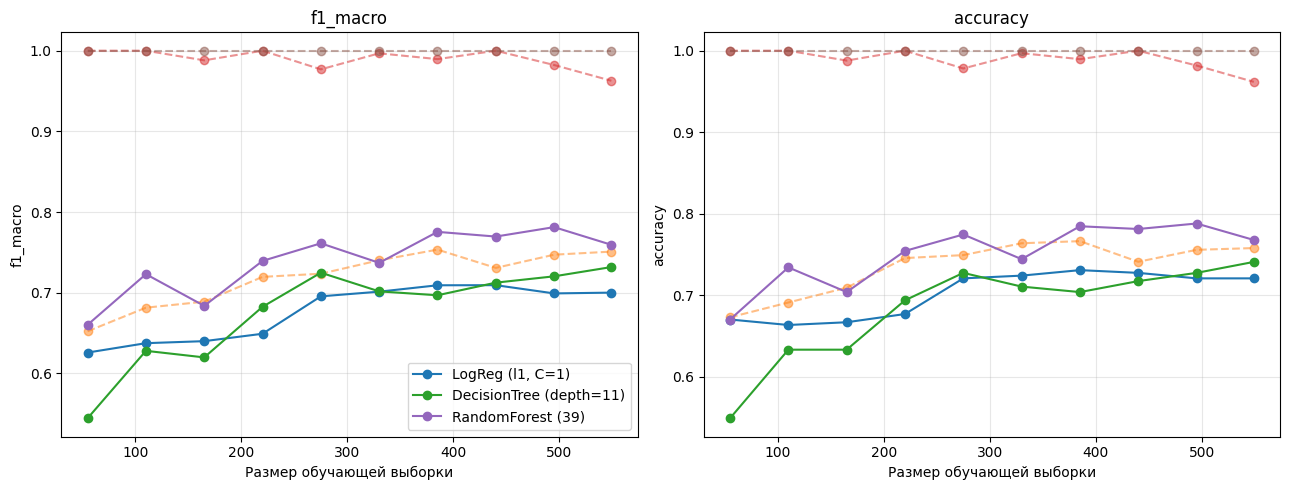

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in ((axes[0], 'f1', 'f1_macro'), (axes[1], 'acc', 'accuracy')):
    for name in models:
        r = results[name]
        ax.plot(train_sizes, r['test_' + metric], marker='o', label=name)
        ax.plot(train_sizes, r['train_' + metric], marker='o',
                linestyle='--', alpha=0.5)
    ax.set_xlabel('Размер обучающей выборки')
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()


**Как читать графики.** Сплошные линии — качество на тесте, пунктирные — на той части train, на которой модель обучалась. Разрыв между ними показывает переобучение, а форма тестовой кривой — чего модели не хватает: данных (кривая ещё растёт) или выразительности (кривая вышла на плато).

**LogReg.** Тест `f1_macro` растёт с 0.626 (55 объектов) до ≈0.71 при 7/10 данных и дальше не меняется; train тоже держится около 0.75. Разрыв train/test мал (≈0.05), и кривая выходит на плато рано. Это классическая картина **доминирования смещения**: линейная модель уже использует данные почти полностью, добавление объектов не помогает — упираемся в предел её выразительности. Поэтому у LogReg и бэггинг не давал прироста (п. 2.6).

**Decision Tree.** Тест `f1_macro` растёт почти линейно: 0.544 → 0.732, и к полному набору ещё не насыщается. При этом train `f1_macro` ≈ 1.0 на малых выборках и 0.963 на полной — дерево запоминает train. Огромный разрыв (≈0.23) означает **доминирование дисперсии**: модель нестабильна, и именно поэтому ей помогает усреднение в ансамбле. По learning curve видно, что дереву в первую очередь нужно больше данных или регуляризация, а не ещё большая глубина.

**Random Forest.** Уже на 110 объектах тест `f1_macro` = 0.723 — заметно выше, чем у одного дерева (0.628) и у LogReg (0.637) при том же объёме. К 5–7/10 кривая выходит на плато ≈0.77, дальше колебания из-за шума тестовой выборки. Train = 1.0 всегда, потому что деревья не ограничены по глубине, но усреднение гасит разброс: разрыв большой, а тестовое качество высокое. Random Forest использует данные эффективнее: ансамбль из 39 деревьев на 110 объектах работает лучше, чем одно дерево на всех 549.

Оговорка: тест содержит всего 297 объектов, поэтому различия в 0.02–0.03 между соседними точками — это шум, а не реальный эффект. Устойчивы только общие тренды: плато у LogReg, продолжающийся рост у дерева и раннее насыщение у Random Forest.


#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [ ]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import log_loss

# xgboost работает с числовыми метками: кодируем классы и запоминаем соответствие.
label_encoder = LabelEncoder().fit(y_train)
dtrain = xgb.DMatrix(X_train, label=label_encoder.transform(y_train))
dtest = xgb.DMatrix(X_test)

base_params = {
    'objective': 'multi:softprob',
    'num_class': len(label_encoder.classes_),
    'eval_metric': 'mlogloss',
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'seed': 42,
}


def cv_mean(cv, column):
    return np.asarray(cv[column])


# Число деревьев не фиксируем: для каждой пары (eta, max_depth) его подбирает
# early stopping по 4-фолдовой CV. Тестовая выборка в подборе не участвует.
cv_results = {}
search_log = []

for eta in (0.05, 0.1, 0.2):
    for depth in (2, 3, 4):
        params = dict(base_params, eta=eta, max_depth=depth)
        cv = xgb.cv(
            params, dtrain,
            num_boost_round=1000,
            nfold=4,
            stratified=True,
            early_stopping_rounds=30,
            verbose_eval=False,
            seed=42,
        )
        cv_results[(eta, depth)] = cv
        losses = cv_mean(cv, 'test-mlogloss-mean')
        best_round = int(np.argmin(losses)) + 1
        search_log.append((float(losses.min()), eta, depth, best_round))
        print('eta=%.2f, max_depth=%d: лучший раунд %3d, CV mlogloss %.4f'
              % (eta, depth, best_round, losses.min()))

best_score, best_eta, best_depth, best_rounds = min(search_log)
print()
print('Лучшая конфигурация: eta=%.2f, max_depth=%d, num_boost_round=%d'
      % (best_eta, best_depth, best_rounds))
print('CV mlogloss: %.3f' % best_score)


In [ ]:
best_cv = cv_results[(best_eta, best_depth)]
test_mean = cv_mean(best_cv, 'test-mlogloss-mean')
test_std = cv_mean(best_cv, 'test-mlogloss-std')
train_mean = cv_mean(best_cv, 'train-mlogloss-mean')
rounds_axis = np.arange(1, len(test_mean) + 1)

plt.figure(figsize=(9, 5))
plt.plot(rounds_axis, test_mean, label='CV mlogloss (mean)')
plt.fill_between(rounds_axis, test_mean - test_std, test_mean + test_std, alpha=0.2)
plt.plot(rounds_axis, train_mean, linestyle='--', label='train mlogloss')
plt.axvline(best_rounds, color='grey', linestyle='--',
            label='лучший раунд = %d' % best_rounds)
plt.xlabel('num_boost_round — число деревьев')
plt.ylabel('mlogloss')
plt.title('XGBoost: CV-кривая (eta=%.2f, max_depth=%d)' % (best_eta, best_depth))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
best_params = dict(base_params, eta=best_eta, max_depth=best_depth)
booster = xgb.train(best_params, dtrain, num_boost_round=best_rounds)

proba_boost = booster.predict(dtest)
y_pred_boost = label_encoder.inverse_transform(proba_boost.argmax(axis=1))

print('Accuracy: %.3f' % accuracy_score(y_test, y_pred_boost))
print('F1 macro: %.3f' % f1_score(y_test, y_pred_boost, average='macro'))
print('Log loss: %.3f' % log_loss(y_test, proba_boost,
                                  labels=label_encoder.classes_))
print()
print(classification_report(y_test, y_pred_boost, digits=3))


**Как подбиралось число деревьев.** Задавать `num_boost_round` вручную бессмысленно: он связан с `eta` (learning rate) и глубиной. Поэтому для каждой пары $(\eta, 	ext{max\_depth})$ запускалась 4-фолдовая стратифицированная CV с `early_stopping_rounds=30`, и брался раунд с минимальным CV `mlogloss`. Тестовая выборка в подборе **не участвовала** — иначе оценка была бы завышенной.

| eta | max_depth | лучший раунд | CV mlogloss |
|---|---|---|---|
| 0.05 | 2 | 420 | 0.516 |
| 0.05 | 3 | 251 | 0.528 |
| 0.05 | 4 | 158 | 0.538 |
| **0.10** | **2** | **251** | **0.513** |
| 0.10 | 3 | 114 | 0.524 |
| 0.10 | 4 | 89 | 0.534 |
| 0.20 | 2 | 93 | 0.516 |
| 0.20 | 3 | 57 | 0.533 |
| 0.20 | 4 | 43 | 0.545 |

**Результаты.** Лучшая конфигурация — `eta=0.1`, `max_depth=2`, 251 дерево; CV `mlogloss` = 0.513 (std по фолдам ≈ 0.04). На тесте: accuracy = 0.791, `f1_macro` = 0.785, log loss = 0.429. По классам: `bus` 0.954, `opel` 0.615, `saab` 0.637, `van` 0.932.

Сравнение со всеми моделями курса:

| Модель | accuracy | f1_macro |
|---|---|---|
| LogReg (2.1) | 0.721 | 0.700 |
| Decision Tree, depth=11 (2.5) | 0.741 | 0.732 |
| Bagging, depth=11 (2.6) | 0.774 | 0.765 |
| Random Forest, 39 деревьев (2.7) | 0.768 | 0.759 |
| **XGBoost (2.9)** | **0.791** | **0.785** |

**Почему бустинг обгоняет бэггинг на табличных данных.** Бэггинг и Random Forest строят деревья **независимо** и усредняют их: это уменьшает **дисперсию**, но не смещение, поэтому качество упирается в предел, определяемый корреляцией деревьев (2.6–2.7). Бустинг строит деревья **последовательно**: каждое новое дерево обучается на ошибках текущего ансамбля (точнее — на отрицательном градиенте функции потерь), то есть ансамбль постепенно уменьшает **смещение**. Итоговая модель — аддитивная композиция слабых learners:

$$F_M(x) = \sum_{m=1}^{M} \eta \, h_m(x),$$

где $h_m$ — дерево небольшой глубины, а $\eta$ — shrinkage. Именно поэтому здесь побеждают **мелкие** деревья (`max_depth=2`): сложность набирается числом деревьев, а не глубиной каждого. Глубокие деревья (4+) переобучаются быстрее — это видно по росту CV `mlogloss` в таблице.

**Почему оптимальное число деревьев так велико (≈250 против 30–40 у бэггинга).** В бэггинге добавление деревьев снижает дисперсию, но она быстро насыщается из-за корреляции. В бустинге каждое дерево — маленький шаг по градиенту, и чтобы пройти путь до минимума, шагов нужно много; чем меньше $\eta$, тем больше деревьев (при $\eta=0.05$ — 420, при $\eta=0.2$ — 93). Произведение «число деревьев × eta» примерно постоянно, что и видно в таблице.

**Что показывает CV-кривая.** Train `mlogloss` монотонно падает до ≈0.14 — ансамбль всё лучше подгоняет train. CV-кривая достигает минимума на 251-м дереве и дальше растёт: начинается переобучение. Early stopping выбирает как раз точку минимума, поэтому «оптимальное число деревьев» — это не максимум качества на train, а минимум на отложенных фолдах.
